# Comparación entre Servicios de Salud Metropolitanos

**Propósito:** aplicar la misma preparación y los mismos KPI del `EDA.ipynb` (Servicio de Salud Metropolitano Central) a los demás Servicios de Salud Metropolitanos, para comparar resultados con definiciones idénticas.

**Fuente:** Portal de Transparencia, nómina de personal a contrata, archivos mensuales por servicio.

**Cómo agregar un servicio (por ejemplo, Sur):** copiar sus CSV en `Data/` con el prefijo del servicio (`Sur_TransparenciaActiva_AAAA-MM.csv`) y volver a ejecutar el notebook completo. Los servicios sin archivos se omiten automáticamente.

**Integrantes:** Alessandro Lavezzi - José Saavedra

In [36]:
import pandas as pd
import numpy as np
import seaborn as sbn
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

## 1. Configuración, lectura e integración

- `SERVICIOS`: patrón de archivos de cada servicio. Centro no tiene prefijo, igual que en el `EDA.ipynb`.
- `MESES_ATIPICOS`: meses que se marcan como atípicos en cada servicio. Centro parte con enero de 2025 (sección 4.3 del `EDA.ipynb`); los demás se completan después de revisar los controles de la sección 2.
- Se usan las mismas funciones de conversión del `EDA.ipynb` (montos, horas extra y fechas), aplicadas por igual a todos los servicios.

In [37]:
#CONFIGURACIÓN
DATA_DIR = Path("..") / "Data"

SERVICIOS = {
    "Centro": "TransparenciaActiva_*.csv",
    "Norte": "Norte_TransparenciaActiva_*.csv",
    "Oriente": "Oriente_TransparenciaActiva_*.csv",
    "Occidente": "Occidente_TransparenciaActiva_*.csv",
    "Sur": "Sur_TransparenciaActiva_*.csv",
}
MESES_ATIPICOS = {"Centro": ["2025-01"]}          # completar con los meses atípicos de cada servicio

UMBRAL_PERSISTENCIA = 75                          # % de meses con horas extra
MESES_MINIMOS = 12                                # meses en la nómina para entrar al KPI de persistencia

NOMBRE_CORTO = {"Médicos cirujanos, farmacéuticos, químico-farmacéuticos, bioquímicos, cirujano-dentistas": "Médicos y afines"}
ORDEN_EST = ["Auxiliar", "Administrativo", "Técnico", "Profesional", "Médicos y afines"]
COLOR = dict(zip(SERVICIOS, plt.cm.tab10.colors))  # color fijo por servicio en todas las figuras

In [38]:
#FUNCIONES DE PREPARACIÓN (MISMA LÓGICA QUE EDA.ipynb, SECCIÓN 2)
COLS_MONTO = {
    "Remuneración bruta del mes (incluye bonos e incentivos, asig. especiales, horas extras)": "rem_bruta",
    "Remuneración líquida del mes": "rem_liquida",
    "Rem. adicionales del mes (no inc. en rem. bruta)": "rem_adicionales",
    "Remuneración Bonos incentivos del mes (inc. en rem. bruta)": "bonos",
}
COLS_HHEE = {
    "Montos y horas extraordinarias diurnas del mes(inc. en rem. bruta)": "diurnas",
    "Montos y horas extraordinarias nocturnas del mes(inc. en rem. bruta)": "nocturnas",
    "Montos y horas extraordinarias festivas del mes (inc. en rem. bruta)": "festivas",
}
COLS_FECHA = {
    "Fecha de inicio dd/mm/aa": "fecha_inicio",
    "Fecha de término dd/mm/aa": "fecha_termino",
}

def a_monto(serie):
    limpio = (
        serie.str.replace("$", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.strip()
    )
    return pd.to_numeric(limpio, errors="coerce")

def leer_servicio(servicio, patron):
    tablas, archivos = [], []
    for f in sorted(DATA_DIR.glob(patron)):
        t = pd.read_csv(f, sep=";", encoding="latin-1", dtype=str)
        sin_nombre = [c for c in t.columns if c.startswith("Unnamed")]
        archivos.append({"servicio": servicio, "periodo": f.stem.split("_")[-1], "filas": len(t),
                         "columna_vacia": t[sin_nombre].isna().all().all()})
        t = t.drop(columns=sin_nombre)
        t["periodo"] = f.stem.split("_")[-1]
        tablas.append(t)
    if not tablas:
        return None, None
    t = pd.concat(tablas, ignore_index=True)
    t.insert(0, "servicio", servicio)
    return t, pd.DataFrame(archivos)

def preparar(t):
    t = t.copy()
    control = {"servicio": t["servicio"].iat[0], "filas": len(t)}

    for original, nuevo in COLS_MONTO.items():
        t[nuevo] = a_monto(t[original])
        control[f"no_conv_{nuevo}"] = (t[nuevo].isna() & t[original].notna()).sum()

    for original, tipo in COLS_HHEE.items():
        texto = t[original].str.strip()
        no_tiene = texto.eq("No tiene")
        partes = texto.str.split(":", n=1, expand=True).reindex(columns=[0, 1]).astype("string")
        monto = a_monto(partes[0])
        horas = pd.to_numeric(
            partes[1].str.replace("hrs", "", regex=False)
                     .str.replace(".", "", regex=False)
                     .str.replace(",", ".", regex=False)
                     .str.strip(),
            errors="coerce")
        # dtype "string" produce números nullable (Float64) y comparaciones con <NA>; se pasan a float común
        t[f"monto_{tipo}"] = monto.where(~no_tiene, 0).astype(float)
        t[f"horas_{tipo}"] = horas.where(~no_tiene, 0).astype(float)
        control[f"vacios_{tipo}"] = texto.isna().sum()
        control[f"otro_formato_{tipo}"] = ((monto.isna() | horas.isna()) & ~no_tiene & texto.notna()).sum()

    for original, nuevo in COLS_FECHA.items():
        t[nuevo] = pd.to_datetime(t[original], format="%d/%m/%Y", errors="coerce")
        control[f"no_conv_{nuevo}"] = (t[nuevo].isna() & t[original].notna()).sum()

    t["cargo"] = t["Cargo o función"].str.strip().str.upper().replace({"CHOFER": "CONDUCTOR"})
    return t, control

In [39]:
#LECTURA E INTEGRACIÓN DE TODOS LOS SERVICIOS
tablas_serv, archivos_serv, controles = [], [], []
for servicio, patron in SERVICIOS.items():
    t, archivos = leer_servicio(servicio, patron)
    if t is None:
        print(f"{servicio}: sin archivos, se omite")
        continue
    t, control = preparar(t)
    tablas_serv.append(t)
    archivos_serv.append(archivos)
    controles.append(control)

nomina = pd.concat(tablas_serv, ignore_index=True)
archivos_serv = pd.concat(archivos_serv, ignore_index=True)
SERV = list(nomina["servicio"].unique())
columnas = tablas_serv[0].columns
ORIGINALES = list(columnas[1:columnas.get_loc("periodo") + 1])   # 21 columnas del archivo + periodo

print("Servicios cargados:", SERV)
print("Filas de la tabla unida:", len(nomina), "| suma de filas de los archivos:", archivos_serv["filas"].sum())
print("Columna final vacía en todos los archivos:", archivos_serv["columna_vacia"].all())

cobertura = nomina.groupby("servicio").agg(
    archivos=("periodo", "nunique"),
    desde=("periodo", "min"),
    hasta=("periodo", "max"),
    filas=("periodo", "size"),
    personas=("Nombre completo", "nunique"),
).reindex(SERV)
cobertura

Sur: sin archivos, se omite
Servicios cargados: ['Centro', 'Norte', 'Oriente', 'Occidente']
Filas de la tabla unida: 162822 | suma de filas de los archivos: 162822
Columna final vacía en todos los archivos: True


,archivos,desde,hasta,filas,personas
servicio,,,,,
Centro,24,2024-09,2026-08,44777,2430
Norte,25,2024-09,2026-09,15790,1036
Oriente,25,2024-09,2026-09,47260,2840
Occidente,25,2024-09,2026-09,54995,5388


In [40]:
#FILAS POR MES Y SERVICIO
filas_mes = archivos_serv.pivot_table(index="periodo", columns="servicio", values="filas").reindex(columns=SERV)
filas_mes

servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,1781.000,603.000,1836.000,2251.000
2024-10,1799.000,603.000,1849.000,2265.000
2024-11,1798.000,608.000,1791.000,2282.000
2024-12,1803.000,604.000,1846.000,2367.000
2025-01,1825.000,621.000,1830.000,2333.000
2025-02,1842.000,628.000,1858.000,2373.000
2025-03,1845.000,620.000,1875.000,2060.000
2025-04,1861.000,643.000,1902.000,2122.000
2025-05,1874.000,642.000,1887.000,2346.000


### 1.1 Ventana común

Los servicios no cubren necesariamente los mismos meses (Centro llega a agosto 2026 y los demás a septiembre 2026). Para que los KPI sean comparables, todos se calculan sobre los meses presentes en **todos** los servicios cargados. Se informa cuántas filas quedan fuera por servicio y mes; no se eliminan de `nomina`, solo se excluyen de `nomina_v`.

In [41]:
#VENTANA COMÚN
periodos_por_servicio = nomina.groupby("servicio")["periodo"].apply(set)
VENTANA = sorted(set.intersection(*periodos_por_servicio))
print(f"Ventana común: {VENTANA[0]} a {VENTANA[-1]} ({len(VENTANA)} meses)")

fuera = nomina[~nomina["periodo"].isin(VENTANA)]
print("Filas fuera de la ventana común, por servicio y mes:")
display(fuera.groupby(["servicio", "periodo"]).size().rename("filas").to_frame())

nomina_v = nomina[nomina["periodo"].isin(VENTANA)].copy()
print("Filas antes:", len(nomina), "| después:", len(nomina_v), "| excluidas:", len(nomina) - len(nomina_v))

Ventana común: 2024-09 a 2026-08 (24 meses)
Filas fuera de la ventana común, por servicio y mes:


,,filas
servicio,periodo,
Norte,2026-09,644
Occidente,2026-09,2130
Oriente,2026-09,1874


Filas antes: 162822 | después: 158174 | excluidas: 4648


## 2. Controles de calidad por servicio

Se repiten los controles del `EDA.ipynb` en cada servicio, para detectar problemas de registro propios de cada uno antes de comparar:
1. Valores no convertibles en montos, horas extra y fechas.
2. Valores "-" en remuneraciones adicionales y bonos, por mes.
3. Duplicados exactos.
4. Personas con más de un registro en el mismo mes (unidad de observación).
5. Cambios de estamento entre meses consecutivos (el error de diciembre 2025 en Centro).
6. Horas festivas, derecho a horas extra frente a horas pagadas, región y cargos distintos.
7. Personas con el mismo nombre en más de un servicio.

In [42]:
#CONVERSIONES POR SERVICIO
pd.DataFrame(controles).set_index("servicio")

,filas,no_conv_rem_bruta,no_conv_rem_liquida,no_conv_rem_adicionales,no_conv_bonos,vacios_diurnas,otro_formato_diurnas,vacios_nocturnas,otro_formato_nocturnas,vacios_festivas,otro_formato_festivas,no_conv_fecha_inicio,no_conv_fecha_termino
servicio,,,,,,,,,,,,,
Centro,44777,0,0,1825,3065,0,0,0,0,0,0,0,0
Norte,15790,0,1,4541,4217,0,0,0,2,0,0,0,0
Oriente,47260,0,1875,21837,14712,0,0,0,0,0,0,0,1
Occidente,54995,0,13558,9165,4547,0,0,0,0,0,0,0,354


In [43]:
#VALORES "-" POR MES Y SERVICIO (%)
aux = nomina[["servicio", "periodo"]].copy()
aux["guion_rem_adicionales"] = nomina["rem_adicionales"].isna()
aux["guion_bonos"] = nomina["bonos"].isna()
aux["bonos_positivos"] = nomina["bonos"].gt(0)

for col in ["guion_rem_adicionales", "guion_bonos", "bonos_positivos"]:
    print(col)
    display((aux.pivot_table(index="periodo", columns="servicio", values=col, aggfunc="mean")
                .reindex(columns=SERV) * 100).round(1))

guion_rem_adicionales


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,0.000,28.500,38.100,100.000
2024-10,0.000,29.200,46.100,100.000
2024-11,0.000,29.300,34.500,100.000
2024-12,0.000,29.100,0.000,100.000
2025-01,100.000,29.300,0.000,0.000
2025-02,0.000,30.400,100.000,0.000
2025-03,0.000,29.500,35.300,0.000
2025-04,0.000,27.700,0.000,0.000
2025-05,0.000,26.900,82.400,0.000


guion_bonos


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,0.000,28.500,61.900,0.000
2024-10,0.000,29.200,36.500,100.000
2024-11,0.000,29.300,0.000,100.000
2024-12,3.900,29.100,0.400,0.000
2025-01,0.000,29.300,0.000,0.000
2025-02,0.000,30.400,0.000,0.000
2025-03,0.000,29.500,0.100,0.000
2025-04,0.000,27.700,0.000,0.000
2025-05,80.400,26.900,100.000,0.000


bonos_positivos


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,65.200,0.000,23.900,53.400
2024-10,0.000,0.000,0.000,0.000
2024-11,16.200,0.000,62.900,0.000
2024-12,29.000,0.000,76.900,63.400
2025-01,30.900,0.000,0.000,0.000
2025-02,70.800,0.000,0.000,0.000
2025-03,70.800,0.000,65.700,58.800
2025-04,0.000,0.000,0.000,0.000
2025-05,0.000,0.000,0.000,0.000


In [44]:
#DUPLICADOS EXACTOS Y REGISTROS POR PERSONA-MES
duplicadas = nomina_v[nomina_v.duplicated(subset=ORIGINALES + ["servicio"], keep=False)]
duplicadas_hhee = (duplicadas["horas_diurnas"] + duplicadas["horas_nocturnas"]) > 0

repeticiones = nomina_v.groupby(["servicio", "periodo", "Nombre completo"]).size()

calidad = pd.DataFrame({
    "copias_adicionales": nomina_v.duplicated(subset=ORIGINALES + ["servicio"]).groupby(nomina_v["servicio"]).sum(),
    "filas_duplicadas_con_hhee": duplicadas_hhee.groupby(duplicadas["servicio"]).sum(),
    "filas": nomina_v.groupby("servicio").size(),
    "persona_mes": repeticiones.groupby("servicio").size(),
    "persona_mes_con_mas_de_un_registro": (repeticiones > 1).groupby("servicio").sum(),
    "max_registros_persona_mes": repeticiones.groupby("servicio").max(),
}).reindex(SERV).fillna(0)
calidad["filas_extra_%"] = (calidad["filas"] - calidad["persona_mes"]) / calidad["filas"] * 100
calidad.round(1)

,copias_adicionales,filas_duplicadas_con_hhee,filas,persona_mes,persona_mes_con_mas_de_un_registro,max_registros_persona_mes,filas_extra_%
servicio,,,,,,,
Centro,27,0.000,44777,43120,1507,6,3.700
Norte,0,0.000,15146,14949,197,2,1.300
Oriente,0,0.000,45386,44357,981,4,2.300
Occidente,0,0.000,52865,49144,3159,7,7.000


In [45]:
#CAMBIOS DE ESTAMENTO ENTRE MESES CONSECUTIVOS, POR SERVICIO
est = (nomina_v.groupby(["servicio", "periodo", "Nombre completo"])["Estamento"].first()
               .reset_index().sort_values(["servicio", "Nombre completo", "periodo"]))
est["estamento_mes_anterior"] = est.groupby(["servicio", "Nombre completo"])["Estamento"].shift(1)
cambios = est.dropna(subset=["estamento_mes_anterior"])
cambios = cambios[cambios["Estamento"] != cambios["estamento_mes_anterior"]]

cambios_mes = (cambios.pivot_table(index="periodo", columns="servicio", values="Estamento", aggfunc="size")
                      .reindex(index=VENTANA, columns=SERV).fillna(0).astype(int))
cambios_mes

servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,0,0,0,0
2024-10,0,0,19,1
2024-11,0,1,0,5
2024-12,1,1,4,3
2025-01,2,1,1,2
2025-02,1,2,1,3
2025-03,0,0,6,1
2025-04,0,0,1,3
2025-05,0,2,4,2


In [46]:
#OTROS CONTROLES POR SERVICIO
tiene_hhee_fila = (nomina_v["horas_diurnas"] + nomina_v["horas_nocturnas"]) > 0
otros = pd.DataFrame({
    "filas_con_horas_festivas": (nomina_v["horas_festivas"] > 0).groupby(nomina_v["servicio"]).sum(),
    "hhee_sin_derecho": (tiene_hhee_fila & nomina_v["Derecho a horas extraordinarias"].str.strip().eq("No"))
                        .groupby(nomina_v["servicio"]).sum(),
    "regiones_distintas": nomina_v.groupby("servicio")["Región"].nunique(),
    "cargos_originales": nomina_v.groupby("servicio")["Cargo o función"].nunique(),
    "cargos_normalizados": nomina_v.groupby("servicio")["cargo"].nunique(),
    "estamentos_distintos": nomina_v.groupby("servicio")["Estamento"].nunique(),
}).reindex(SERV)
display(otros)

print("Derecho a horas extraordinarias frente a horas pagadas (filas):")
pd.crosstab([nomina_v["servicio"], nomina_v["Derecho a horas extraordinarias"]], tiene_hhee_fila)

,filas_con_horas_festivas,hhee_sin_derecho,regiones_distintas,cargos_originales,cargos_normalizados,estamentos_distintos
servicio,,,,,,
Centro,0,207,1,95,80,5
Norte,432,120,1,770,744,5
Oriente,1682,1298,2,242,213,5
Occidente,0,420,1,131,116,5


Derecho a horas extraordinarias frente a horas pagadas (filas):


col_0                                      False  True 
servicio  Derecho a horas extraordinarias              
Centro    No                               32555    207
          Sí                                 407  11608
Norte     No                               11081    120
          Sí                                  83   3862
Occidente No                               40018    420
          Sí                                 119  12308
Oriente   No                               36488   1298
          Sí                                1011   6589

In [47]:
#PERSONAS CON EL MISMO NOMBRE EN MÁS DE UN SERVICIO
serv_por_nombre = nomina_v.groupby("Nombre completo")["servicio"].nunique()
print("Nombres presentes en más de un servicio (en algún mes):", (serv_por_nombre > 1).sum())

mismo_mes = nomina_v.groupby(["periodo", "Nombre completo"])["servicio"].nunique()
print("Nombres presentes en más de un servicio en el mismo mes, por mes:")
(mismo_mes > 1).groupby("periodo").sum()

Nombres presentes en más de un servicio (en algún mes): 54
Nombres presentes en más de un servicio en el mismo mes, por mes:


periodo
2024-09    1
2024-10    2
2024-11    2
2024-12    1
2025-01    2
2025-02    1
2025-03    3
2025-04    1
2025-05    1
2025-06    1
2025-07    1
2025-08    2
2025-09    2
2025-10    5
2025-11    3
2025-12    3
2026-01    3
2026-02    4
2026-03    4
2026-04    4
2026-05    3
2026-06    4
2026-07    2
2026-08    3
Name: servicio, dtype: int64

## 3. Tabla persona-mes y KPI por servicio

Se construye la misma tabla persona-mes del `EDA.ipynb`, ahora con clave **(servicio, periodo, nombre)**. La persona se identifica por **(servicio, nombre)**: un mismo nombre en dos servicios se cuenta como dos personas, porque no hay RUT para unirlos (sección 2).

- Estamento: el más frecuente de cada persona dentro de su servicio (igual que `estamento_modal`).
- Marcas: `flag_rem_cero`, `flag_pct_imposible`, `flag_mes_atipico` (según `MESES_ATIPICOS`) y `flag_horas_extremas`, con el límite Q3 + 1,5·RIQ calculado **dentro de cada servicio**.

In [48]:
#TABLA PERSONA-MES DE TODOS LOS SERVICIOS
CLAVE = ["servicio", "periodo", "Nombre completo"]
pm_all = (
    nomina_v.groupby(CLAVE)
            .agg(
                horas_diurnas=("horas_diurnas", "sum"),
                horas_nocturnas=("horas_nocturnas", "sum"),
                monto_diurnas=("monto_diurnas", "sum"),
                monto_nocturnas=("monto_nocturnas", "sum"),
                rem_bruta=("rem_bruta", "sum"),
            )
            .reset_index()
)
pm_all["horas_hhee"] = pm_all["horas_diurnas"] + pm_all["horas_nocturnas"]
pm_all["monto_hhee"] = pm_all["monto_diurnas"] + pm_all["monto_nocturnas"]
pm_all["tiene_hhee"] = pm_all["horas_hhee"] > 0
pm_all["sobre_40"] = pm_all["horas_diurnas"] > 40
pm_all["pct_hhee_en_rem"] = np.where(pm_all["rem_bruta"] > 0, pm_all["monto_hhee"] / pm_all["rem_bruta"] * 100, np.nan)

idx_persona = pd.MultiIndex.from_frame(pm_all[["servicio", "Nombre completo"]])
estamento_modal = (nomina_v.groupby(["servicio", "Nombre completo"])["Estamento"]
                           .agg(lambda s: s.mode().iloc[0]).replace(NOMBRE_CORTO))
pm_all["estamento"] = estamento_modal.reindex(idx_persona).to_numpy()

# Marcas de calidad
limites = pm_all[pm_all["tiene_hhee"]].groupby("servicio")["horas_hhee"].quantile([0.25, 0.75]).unstack()
limites["limite_extremo"] = limites[0.75] + 1.5 * (limites[0.75] - limites[0.25])
pm_all["flag_mes_atipico"] = [p in MESES_ATIPICOS.get(s, []) for s, p in zip(pm_all["servicio"], pm_all["periodo"])]
pm_all["flag_rem_cero"] = pm_all["rem_bruta"] <= 0
pm_all["flag_pct_imposible"] = pm_all["pct_hhee_en_rem"] > 100
pm_all["flag_horas_extremas"] = pm_all["horas_hhee"] > pm_all["servicio"].map(limites["limite_extremo"])

print("Persona-mes:", len(pm_all))
print("\nLímite de valor extremo por servicio (horas):")
display(limites.reindex(SERV).round(1))
print("Persona-mes marcadas por servicio:")
display(pm_all.groupby("servicio")[[c for c in pm_all.columns if c.startswith("flag_")]].sum().reindex(SERV))

print("Control de la agregación (¿la suma es igual en la nómina y en persona-mes?):")
for col in ["horas_diurnas", "horas_nocturnas", "monto_diurnas", "monto_nocturnas", "rem_bruta"]:
    iguales = nomina_v.groupby("servicio")[col].sum().eq(pm_all.groupby("servicio")[col].sum())
    print(f"{col}: {iguales.all()}")
print("Persona-mes sin estamento asignado:", pm_all["estamento"].isna().sum())

Persona-mes: 151570

Límite de valor extremo por servicio (horas):


,0.250,0.750,limite_extremo
servicio,,,
Centro,15.000,72.000,157.500
Norte,16.000,48.000,96.000
Oriente,12.000,46.000,97.000
Occidente,12.000,59.000,129.500


Persona-mes marcadas por servicio:


,flag_mes_atipico,flag_rem_cero,flag_pct_imposible,flag_horas_extremas
servicio,,,,
Centro,1756,173,9,486
Norte,0,47,1,147
Oriente,0,58,2,490
Occidente,0,1102,110,486


Control de la agregación (¿la suma es igual en la nómina y en persona-mes?):
horas_diurnas: True
horas_nocturnas: True
monto_diurnas: True
monto_nocturnas: True
rem_bruta: True
Persona-mes sin estamento asignado: 0


In [49]:
#PERSISTENCIA POR PERSONA
personas_all = (
    pm_all.groupby(["servicio", "Nombre completo"])
          .agg(
              estamento=("estamento", "first"),
              meses_presente=("periodo", "nunique"),
              meses_con_hhee=("tiene_hhee", "sum"),
          )
          .reset_index()
)
personas_all["pct_meses_con_hhee"] = personas_all["meses_con_hhee"] / personas_all["meses_presente"] * 100
p12_all = personas_all[personas_all["meses_presente"] >= MESES_MINIMOS].copy()
p12_all["persistente"] = (p12_all["pct_meses_con_hhee"] >= UMBRAL_PERSISTENCIA).astype(bool)

# personas con menos de 12 meses no están en p12_all: quedan como no persistentes (False), no como NaN
persistente = p12_all.set_index(["servicio", "Nombre completo"])["persistente"]
pm_all["persistente"] = persistente.reindex(idx_persona).fillna(False).astype(bool).to_numpy()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_14764\286358841.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pm_all["persistente"] = persistente.reindex(idx_persona).fillna(False).astype(bool).to_numpy()


In [50]:
#KPI POR SERVICIO
def calcular_kpis(pm, umbral=UMBRAL_PERSISTENCIA):
    por_persona = pm.groupby(["servicio", "Nombre completo"]).agg(
        meses_presente=("periodo", "nunique"),
        meses_con_hhee=("tiene_hhee", "sum"),
    )
    base = por_persona[por_persona["meses_presente"] >= MESES_MINIMOS]
    persistente = base["meses_con_hhee"] / base["meses_presente"] * 100 >= umbral
    peso = pm.loc[pm["tiene_hhee"] & (pm["rem_bruta"] > 0), "pct_hhee_en_rem"]
    con_diurnas = (pm["horas_diurnas"] > 0).sum()
    return pd.Series({
        "persona_mes": len(pm),
        "personas": len(por_persona),
        "personas_12m": len(base),
        "persistentes": persistente.sum(),
        "tasa_persistencia_%": persistente.mean() * 100,
        "frecuencia_%": pm["tiene_hhee"].mean() * 100,
        "peso_mediana_%": peso.median(),
        "mediana_horas_con_hhee": pm.loc[pm["tiene_hhee"], "horas_hhee"].median(),
        "sobre_40_%_con_diurnas": pm["sobre_40"].sum() / con_diurnas * 100 if con_diurnas else np.nan,
        "gasto_hhee_MM": pm["monto_hhee"].sum() / 1e6,
        "gasto_por_persona_mes": pm["monto_hhee"].sum() / len(pm),
    })

def kpis_por_servicio(pm, **kw):
    tabla = pm.groupby("servicio")[pm.columns].apply(lambda g: calcular_kpis(g, **kw)).reindex(SERV)
    tabla.loc["Total"] = calcular_kpis(pm, **kw)
    return tabla

tabla_kpi = kpis_por_servicio(pm_all)
tabla_kpi.round(1)

,persona_mes,personas,personas_12m,persistentes,tasa_persistencia_%,frecuencia_%,peso_mediana_%,mediana_horas_con_hhee,sobre_40_%_con_diurnas,gasto_hhee_MM,gasto_por_persona_mes
servicio,,,,,,,,,,,
Centro,43120.000,2430.000,1776.000,364.000,20.500,27.400,14.600,36.000,1.700,3426.500,79464.000
Norte,14949.000,871.000,611.000,135.000,22.100,26.600,10.900,25.000,0.600,1179.500,78900.700
Oriente,44357.000,2817.000,1815.000,151.000,8.300,17.700,8.100,23.000,0.100,1235.600,27855.500
Occidente,49144.000,5337.000,1931.000,304.000,15.700,25.400,10.400,29.000,0.400,3137.900,63851.400
Total,151570.000,11455.000,6133.000,954.000,15.600,23.800,10.900,29.000,0.900,8979.500,59243.100


In [51]:
#VALIDACIÓN: CENTRO DEBE REPRODUCIR EL EDA.ipynb (solo si la ventana común son los mismos 24 meses)
esperado_centro = {"persona_mes": 43120, "personas": 2430, "personas_12m": 1776, "persistentes": 364}
if "Centro" in SERV:
    print("Ventana común = 2024-09 a 2026-08:", VENTANA[0] == "2024-09" and VENTANA[-1] == "2026-08")
    for k, v in esperado_centro.items():
        obtenido = tabla_kpi.loc["Centro", k]
        print(f"{k}: EDA2 = {obtenido:.0f} | EDA = {v} | coincide: {obtenido == v}")

Ventana común = 2024-09 a 2026-08: True
persona_mes: EDA2 = 43120 | EDA = 43120 | coincide: True
personas: EDA2 = 2430 | EDA = 2430 | coincide: True
personas_12m: EDA2 = 1776 | EDA = 1776 | coincide: True
persistentes: EDA2 = 364 | EDA = 364 | coincide: True


## 4. Comparación por estamento

Los servicios pueden diferir en su composición por estamento. Como la persistencia cambia mucho entre estamentos (sección 7 del `EDA.ipynb`), una diferencia en la tasa total puede deberse solo a la composición (paradoja de Simpson). Se revisa:
- **Composición** de cada servicio por estamento (proporción de segmento).
- **Persistencia, frecuencia y peso** por estamento y servicio.
- **Tasa de persistencia estandarizada** por estamento: la tasa que tendría cada servicio si tuviera la composición por estamento del total de servicios (estandarización directa).

% de persona-mes por estamento:


estamento,Auxiliar,Administrativo,Técnico,Profesional,Médicos y afines
servicio,,,,,
Centro,6.900,13.700,19.400,40.800,19.200
Norte,2.800,9.900,13.300,46.500,27.600
Oriente,6.600,8.800,21.500,44.200,18.900
Occidente,4.200,11.100,20.500,36.200,28.000


% de personas con ≥12 meses por estamento (denominador de persistencia):


estamento,Auxiliar,Administrativo,Técnico,Profesional,Médicos y afines
servicio,,,,,
Centro,6.800,13.500,19.300,40.800,19.700
Norte,2.800,9.700,13.600,46.300,27.700
Oriente,6.400,8.600,21.400,44.400,19.100
Occidente,4.000,11.200,19.400,36.000,29.300


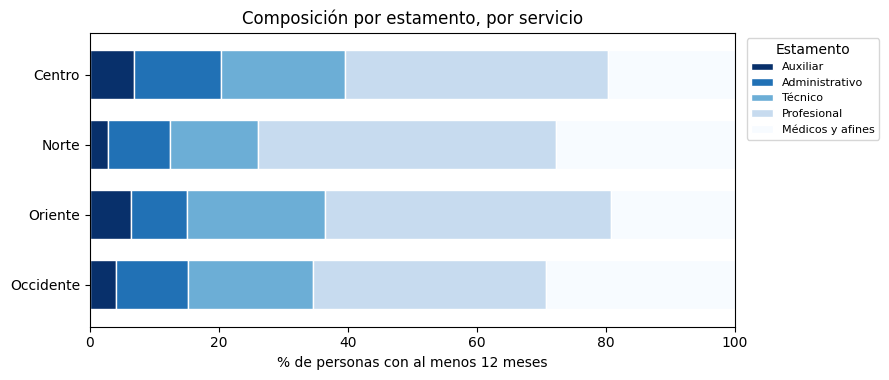

In [52]:
#COMPOSICIÓN POR ESTAMENTO (%)
comp_pm = pd.crosstab(pm_all["servicio"], pm_all["estamento"], normalize="index").reindex(index=SERV, columns=ORDEN_EST) * 100
comp_p12 = pd.crosstab(p12_all["servicio"], p12_all["estamento"], normalize="index").reindex(index=SERV, columns=ORDEN_EST) * 100
print("% de persona-mes por estamento:")
display(comp_pm.round(1))
print(f"% de personas con ≥{MESES_MINIMOS} meses por estamento (denominador de persistencia):")
display(comp_p12.round(1))

#FIGURA C1: COMPOSICIÓN POR ESTAMENTO
fig, ax = plt.subplots(figsize=(9, 0.6 * len(SERV) + 1.5))
comp_p12.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, colormap="Blues_r", edgecolor="white", width=0.7)
ax.set_xlabel(f"% de personas con al menos {MESES_MINIMOS} meses")
ax.set_ylabel("")
ax.set_title("Composición por estamento, por servicio")
ax.set_xlim(0, 100)
ax.legend(title="Estamento", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c1_composicion_estamento.png", dpi=150)
plt.show()

In [53]:
#KPI POR ESTAMENTO Y SERVICIO
n_est = (p12_all.pivot_table(index="estamento", columns="servicio", values="persistente", aggfunc="size")
                .reindex(index=ORDEN_EST, columns=SERV))
pers_est = (p12_all.pivot_table(index="estamento", columns="servicio", values="persistente", aggfunc="mean")
                   .reindex(index=ORDEN_EST, columns=SERV) * 100)
frec_est = (pm_all.pivot_table(index="estamento", columns="servicio", values="tiene_hhee", aggfunc="mean")
                  .reindex(index=ORDEN_EST, columns=SERV) * 100)
base_peso = pm_all[pm_all["tiene_hhee"] & (pm_all["rem_bruta"] > 0)]
peso_est = (base_peso.pivot_table(index="estamento", columns="servicio", values="pct_hhee_en_rem", aggfunc="median")
                     .reindex(index=ORDEN_EST, columns=SERV))

print(f"Personas con ≥{MESES_MINIMOS} meses, por estamento:")
display(n_est)
print("Tasa de persistencia (%):")
display(pers_est.round(1))
print("Frecuencia de horas extra (% de persona-mes):")
display(frec_est.round(1))
print("Peso de las horas extra en la remuneración bruta (mediana, %):")
display(peso_est.round(1))

Personas con ≥12 meses, por estamento:


servicio,Centro,Norte,Oriente,Occidente
estamento,,,,
Auxiliar,121,17,117,77
Administrativo,239,59,156,217
Técnico,342,83,389,375
Profesional,724,283,806,696
Médicos y afines,350,169,347,566


Tasa de persistencia (%):


servicio,Centro,Norte,Oriente,Occidente
estamento,,,,
Auxiliar,55.400,76.500,19.700,44.200
Administrativo,44.800,49.200,23.700,24.000
Técnico,18.400,55.400,10.300,20.800
Profesional,16.300,11.000,6.000,17.800
Médicos y afines,2.600,9.500,0.900,2.800


Frecuencia de horas extra (% de persona-mes):


servicio,Centro,Norte,Oriente,Occidente
estamento,,,,
Auxiliar,66.300,71.700,35.400,53.000
Administrativo,50.200,58.700,30.200,33.500
Técnico,28.700,63.500,26.500,36.800
Profesional,23.600,14.100,14.700,27.700
Médicos y afines,3.900,14.000,3.100,6.700


Peso de las horas extra en la remuneración bruta (mediana, %):


servicio,Centro,Norte,Oriente,Occidente
estamento,,,,
Auxiliar,24.800,11.500,10.100,16.100
Administrativo,12.800,8.900,8.600,8.800
Técnico,15.400,12.900,7.600,10.400
Profesional,11.000,11.900,7.800,9.800
Médicos y afines,20.400,7.200,4.200,12.100


In [54]:
#TASA DE PERSISTENCIA ESTANDARIZADA POR ESTAMENTO
composicion_ref = p12_all["estamento"].value_counts(normalize=True).reindex(ORDEN_EST)

estandarizacion = pd.DataFrame({
    "tasa_bruta_%": p12_all.groupby("servicio")["persistente"].mean().reindex(SERV) * 100,
    "tasa_estandarizada_%": pers_est.mul(composicion_ref, axis=0).sum(min_count=1)
                            / pers_est.notna().mul(composicion_ref, axis=0).sum(),
})
estandarizacion["diferencia_pp"] = estandarizacion["tasa_estandarizada_%"] - estandarizacion["tasa_bruta_%"]
print("Composición de referencia (total de servicios, %):")
print((composicion_ref * 100).round(1))
estandarizacion.round(1)

Composición de referencia (total de servicios, %):
estamento
Auxiliar            5.400
Administrativo     10.900
Técnico            19.400
Profesional        40.900
Médicos y afines   23.300
Name: proportion, dtype: float64


,tasa_bruta_%,tasa_estandarizada_%,diferencia_pp
servicio,,,
Centro,20.500,18.700,-1.800
Norte,22.100,27.000,4.900
Oriente,8.300,8.300,-0.000
Occidente,15.700,17.000,1.200


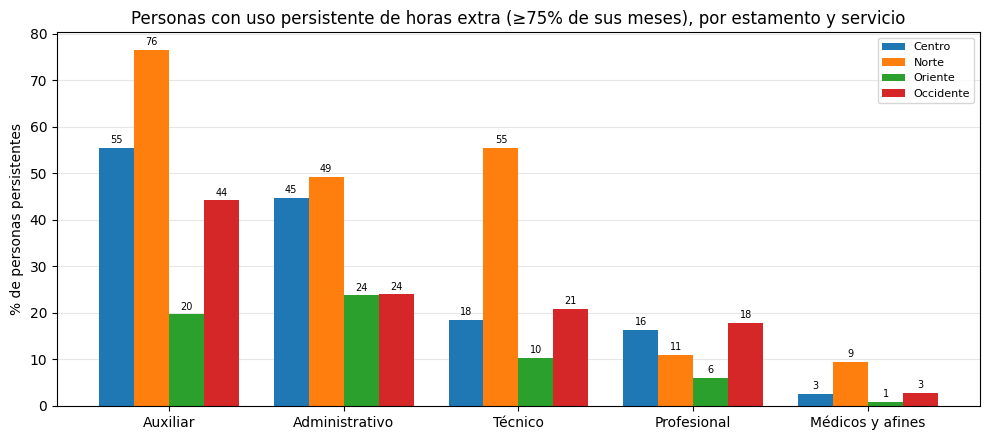

In [55]:
#FIGURA C2: PERSISTENCIA POR ESTAMENTO Y SERVICIO
x = np.arange(len(ORDEN_EST))
ancho = 0.8 / len(SERV)

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, s in enumerate(SERV):
    barras = ax.bar(x + (i - (len(SERV) - 1) / 2) * ancho, pers_est[s], width=ancho, color=COLOR[s], label=s)
    ax.bar_label(barras, labels=[f"{v:.0f}" if pd.notna(v) else "" for v in pers_est[s]], fontsize=7, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(ORDEN_EST)
ax.set_ylabel("% de personas persistentes")
ax.set_title(f"Personas con uso persistente de horas extra (≥{UMBRAL_PERSISTENCIA}% de sus meses), por estamento y servicio")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c2_persistencia_estamento_servicio.png", dpi=150)
plt.show()

## 5. Distribuciones por servicio

Se comparan las tres variables que sostienen los KPI, con las mismas medidas robustas del `EDA.ipynb` (mediana, RIQ, MAD):
- Horas extra por persona-mes, entre quienes tienen horas extra.
- Peso de las horas extra en la remuneración bruta, entre quienes tienen horas extra y remuneración mayor que cero.
- Porcentaje de meses con horas extra por persona (presentes ≥ 12 meses), la variable sobre la que se aplica el umbral.

In [56]:
#RESUMEN DE DISTRIBUCIONES POR SERVICIO
def resumen_dist(s):
    return pd.Series({
        "n": s.count(),
        "media": s.mean(),
        "mediana": s.median(),
        "desv_est": s.std(),
        "RIQ": s.quantile(0.75) - s.quantile(0.25),
        "MAD": (s - s.median()).abs().median(),
        "p95": s.quantile(0.95),
        "max": s.max(),
    })

con_all = pm_all[pm_all["tiene_hhee"]]
print("Horas extra por persona-mes (con horas extra):")
display(con_all.groupby("servicio")["horas_hhee"].apply(resumen_dist).unstack().reindex(SERV).round(1))
print("Peso de las horas extra en la remuneración bruta, % (con horas extra y rem. > 0):")
display(base_peso.groupby("servicio")["pct_hhee_en_rem"].apply(resumen_dist).unstack().reindex(SERV).round(1))
print(f"% de meses con horas extra por persona (presentes ≥ {MESES_MINIMOS} meses):")
display(p12_all.groupby("servicio")["pct_meses_con_hhee"].apply(resumen_dist).unstack().reindex(SERV).round(1))

Horas extra por persona-mes (con horas extra):


,n,media,mediana,desv_est,RIQ,MAD,p95,max
servicio,,,,,,,,
Centro,11805.000,51.100,36.000,48.800,57.000,24.000,147.000,431.000
Norte,3982.000,35.600,25.000,29.200,32.000,13.000,94.000,206.000
Oriente,7873.000,33.400,23.000,32.100,34.000,14.000,105.000,543.000
Occidente,12479.000,42.900,29.000,41.800,47.000,18.000,122.000,770.000


Peso de las horas extra en la remuneración bruta, % (con horas extra y rem. > 0):


,n,media,mediana,desv_est,RIQ,MAD,p95,max
servicio,,,,,,,,
Centro,11802.000,17.200,14.600,14.300,17.500,8.700,41.500,451.600
Norte,3982.000,14.700,10.900,15.600,12.400,5.800,38.400,106.500
Oriente,7872.000,10.300,8.100,8.800,10.000,4.600,26.600,131.800
Occidente,12425.000,19.200,10.400,291.000,13.900,6.000,45.800,31815.400


% de meses con horas extra por persona (presentes ≥ 12 meses):


,n,media,mediana,desv_est,RIQ,MAD,p95,max
servicio,,,,,,,,
Centro,1776.000,27.800,0.000,37.300,58.300,0.000,100.000,100.000
Norte,611.000,26.700,0.000,39.200,62.500,0.000,100.000,100.000
Oriente,1815.000,17.900,0.000,28.000,26.100,0.000,83.300,100.000
Occidente,1931.000,25.700,4.300,33.600,52.200,4.300,91.300,100.000


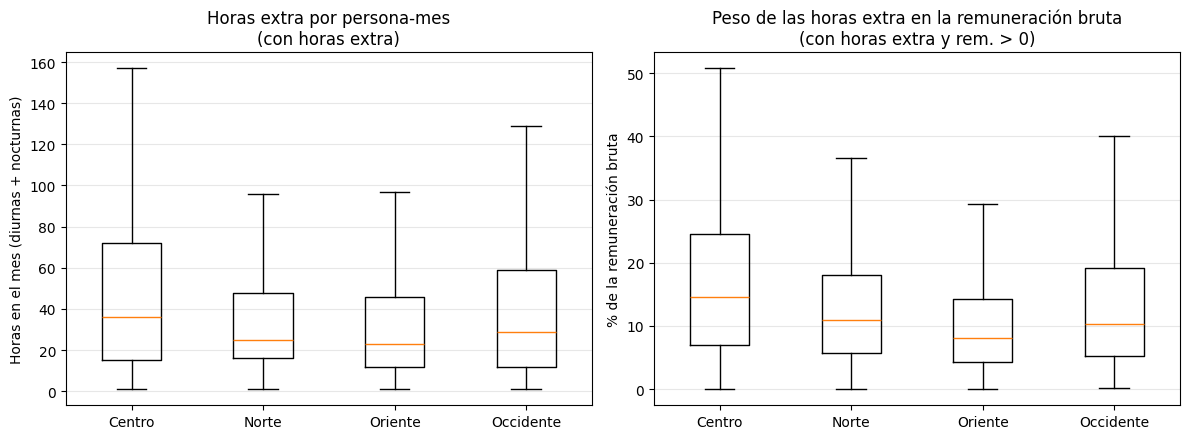

In [57]:
#FIGURA C3: DISTRIBUCIÓN DE HORAS Y PESO POR SERVICIO
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot([con_all.loc[con_all["servicio"] == s, "horas_hhee"] for s in SERV], showfliers=False)
axes[0].set_title("Horas extra por persona-mes\n(con horas extra)")
axes[0].set_ylabel("Horas en el mes (diurnas + nocturnas)")

axes[1].boxplot([base_peso.loc[base_peso["servicio"] == s, "pct_hhee_en_rem"] for s in SERV], showfliers=False)
axes[1].set_title("Peso de las horas extra en la remuneración bruta\n(con horas extra y rem. > 0)")
axes[1].set_ylabel("% de la remuneración bruta")

for ax in axes:
    ax.set_xticks(range(1, len(SERV) + 1))
    ax.set_xticklabels(SERV)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c3_distribucion_horas_peso.png", dpi=150)
plt.show()

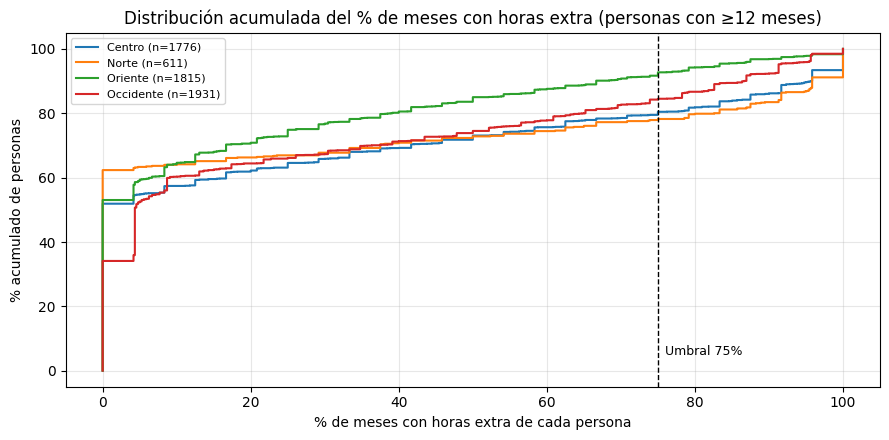

In [58]:
#FIGURA C4: DISTRIBUCIÓN ACUMULADA DEL % DE MESES CON HORAS EXTRA
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SERV:
    v = np.sort(p12_all.loc[p12_all["servicio"] == s, "pct_meses_con_hhee"])
    ax.step(v, np.arange(1, len(v) + 1) / len(v) * 100, where="post", color=COLOR[s], label=f"{s} (n={len(v)})")
ax.axvline(UMBRAL_PERSISTENCIA, color="black", linestyle="--", linewidth=1)
ax.text(UMBRAL_PERSISTENCIA + 1, 5, f"Umbral {UMBRAL_PERSISTENCIA}%", fontsize=9)
ax.set_xlabel("% de meses con horas extra de cada persona")
ax.set_ylabel("% acumulado de personas")
ax.set_title(f"Distribución acumulada del % de meses con horas extra (personas con ≥{MESES_MINIMOS} meses)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c4_ecdf_persistencia_servicio.png", dpi=150)
plt.show()

## 6. Serie mensual y comparación entre años

- **Serie mensual por servicio** de la frecuencia, los casos sobre 40 horas diurnas, la mediana del monto pagado por hora, el peso y el gasto. El monto por hora sirve como control de registro: un cambio brusco en un mes sugiere un cambio en la forma de informar los montos (como agosto 2025 en Centro).
- **Comparación entre los dos años** (septiembre a agosto), en total y por estamento, para cada servicio.

In [59]:
#SERIE MENSUAL POR SERVICIO
con_all = pm_all[pm_all["tiene_hhee"]].copy()
con_all["monto_por_hora"] = con_all["monto_hhee"] / con_all["horas_hhee"]

frec_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="tiene_hhee", aggfunc="mean").reindex(columns=SERV) * 100
sobre_40_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="sobre_40", aggfunc="sum").reindex(columns=SERV)
monto_hora_mes = con_all.pivot_table(index="periodo", columns="servicio", values="monto_por_hora", aggfunc="median").reindex(columns=SERV)
peso_mes = base_peso.pivot_table(index="periodo", columns="servicio", values="pct_hhee_en_rem", aggfunc="median").reindex(columns=SERV)
gasto_mes = pm_all.pivot_table(index="periodo", columns="servicio", values="monto_hhee", aggfunc="sum").reindex(columns=SERV) / 1e6

print("Frecuencia mensual (%):");                        display(frec_mes.round(1))
print("Persona-mes con más de 40 horas diurnas:");       display(sobre_40_mes)
print("Mediana del monto pagado por hora ($):");          display(monto_hora_mes.round(0))
print("Mediana del peso en la remuneración bruta (%):");  display(peso_mes.round(1))
print("Gasto mensual en horas extra (millones de $):");   display(gasto_mes.round(1))

Frecuencia mensual (%):


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,29.800,30.800,23.700,22.600
2024-10,29.800,30.900,20.400,23.500
2024-11,29.800,32.000,20.700,22.900
2024-12,29.700,28.700,19.600,23.700
2025-01,29.600,29.800,19.800,22.900
2025-02,27.700,25.500,18.900,27.700
2025-03,27.800,28.600,16.700,25.300
2025-04,28.200,25.400,17.100,24.700
2025-05,28.400,27.400,13.200,23.300


Persona-mes con más de 40 horas diurnas:


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,2,0,0,1
2024-10,2,0,0,0
2024-11,2,0,0,1
2024-12,6,0,0,1
2025-01,99,1,1,1
2025-02,6,1,0,5
2025-03,4,1,0,2
2025-04,8,1,1,1
2025-05,5,2,1,4


Mediana del monto pagado por hora ($):


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,4662.000,5748.000,4634.000,4113.000
2024-10,4556.000,5677.000,4787.000,4622.000
2024-11,4438.000,5677.000,4778.000,4110.000
2024-12,4558.000,5810.000,4393.000,4312.000
2025-01,4644.000,5848.000,4488.000,4373.000
2025-02,4498.000,5765.000,4512.000,4232.000
2025-03,4646.000,6099.000,4539.000,4367.000
2025-04,4626.000,5951.000,4560.000,4512.000
2025-05,4738.000,7258.000,4671.000,4693.000


Mediana del peso en la remuneración bruta (%):


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,14.400,10.900,8.700,12.600
2024-10,14.400,12.800,9.800,15.300
2024-11,14.800,11.600,10.000,11.000
2024-12,15.400,9.400,8.300,12.400
2025-01,20.400,9.100,9.000,12.500
2025-02,16.000,12.800,9.200,11.400
2025-03,14.700,8.900,7.200,7.900
2025-04,20.500,12.300,8.600,11.500
2025-05,15.200,12.400,3.900,10.900


Gasto mensual en horas extra (millones de $):


servicio,Centro,Norte,Oriente,Occidente
periodo,,,,
2024-09,152.700,56.000,65.100,111.300
2024-10,147.100,53.200,65.900,147.700
2024-11,155.100,55.300,66.400,118.800
2024-12,156.000,44.900,53.900,129.700
2025-01,191.800,47.800,61.500,137.900
2025-02,142.300,43.000,60.000,138.100
2025-03,145.100,49.800,44.500,118.000
2025-04,178.600,45.600,51.200,129.300
2025-05,153.000,52.600,18.900,127.900


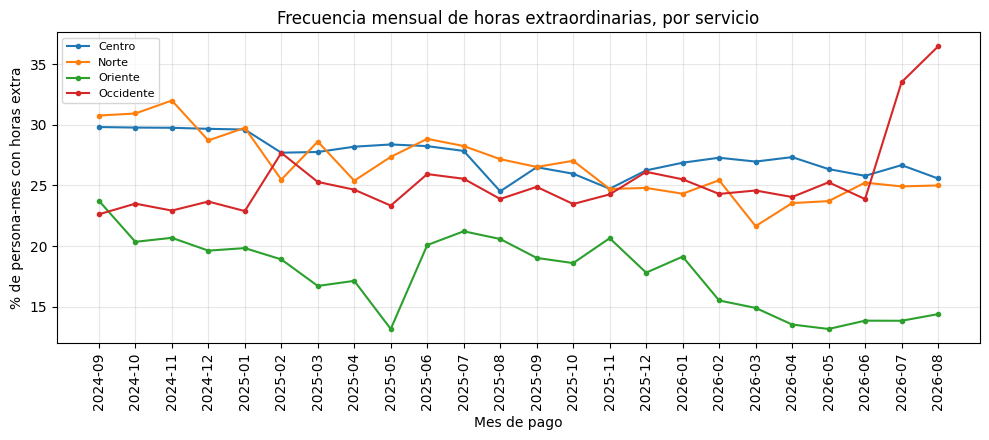

In [60]:
#FIGURA C5: FRECUENCIA MENSUAL POR SERVICIO
fig, ax = plt.subplots(figsize=(10, 4.5))
for s in SERV:
    ax.plot(frec_mes.index, frec_mes[s], marker="o", markersize=3, linewidth=1.5, color=COLOR[s], label=s)
ax.set_title("Frecuencia mensual de horas extraordinarias, por servicio")
ax.set_xlabel("Mes de pago")
ax.set_ylabel("% de persona-mes con horas extra")
ax.tick_params(axis="x", rotation=90)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c5_frecuencia_mensual_servicio.png", dpi=150)
plt.show()

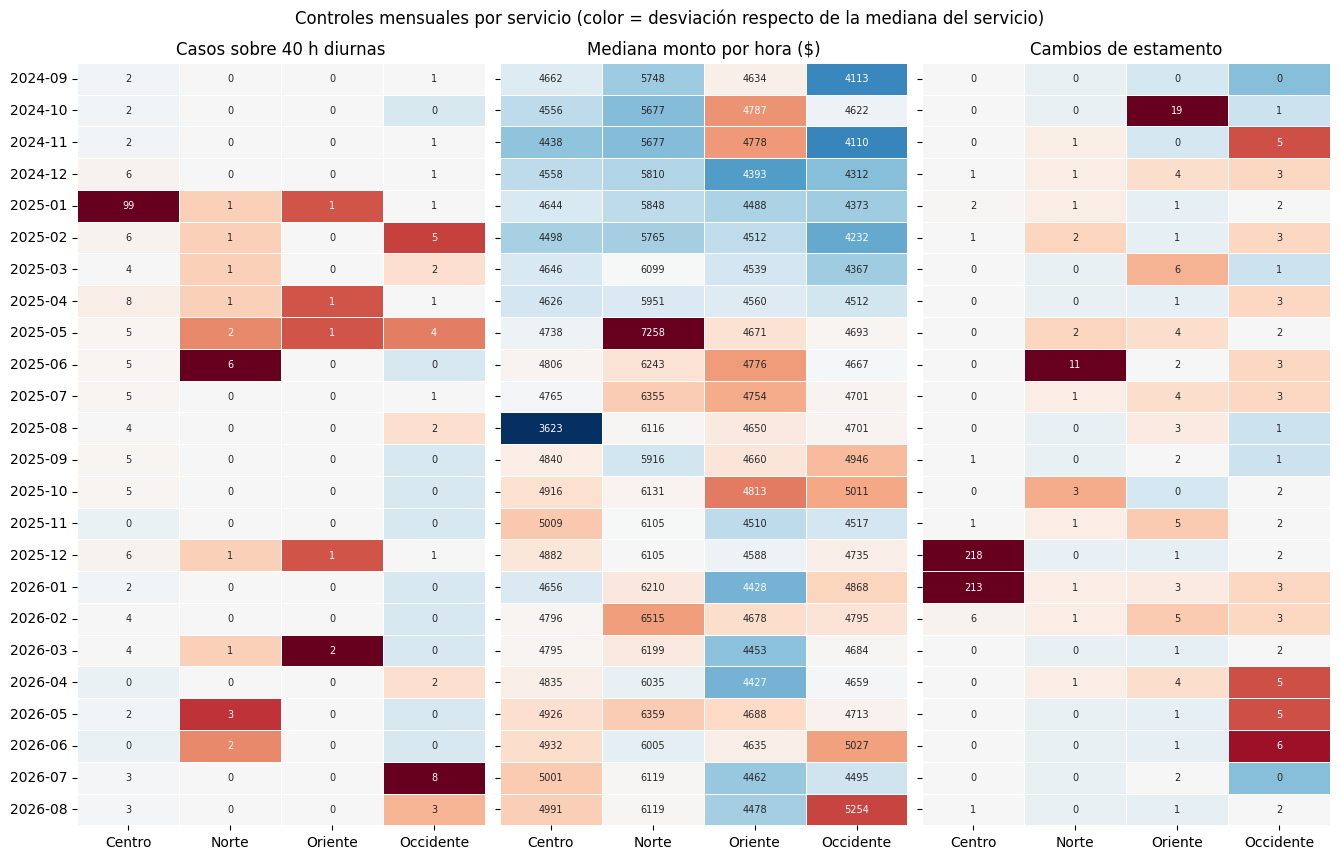

In [61]:
#FIGURA C6: CONTROLES MENSUALES DE REGISTRO (MAPAS DE CALOR)
# El color se normaliza dentro de cada servicio (columna), para ver meses que se apartan del resto de su propio servicio
paneles = {
    "Casos sobre 40 h diurnas": sobre_40_mes,
    "Mediana monto por hora ($)": monto_hora_mes,
    "Cambios de estamento": cambios_mes,
}
fig, axes = plt.subplots(1, len(paneles), figsize=(4.5 * len(paneles), 0.28 * len(VENTANA) + 2), sharey=True)
for ax, (titulo, tabla) in zip(axes, paneles.items()):
    tabla = tabla.apply(pd.to_numeric, errors="coerce").astype(float)   # las tablas dinámicas pueden quedar con dtype object
    z = (tabla - tabla.median()) / tabla.std().replace(0, np.nan)       # desviación 0 (columna constante) queda sin color
    sbn.heatmap(z, cmap="RdBu_r", center=0, vmin=-3, vmax=3, annot=tabla, fmt=".0f",
                annot_kws={"size": 7}, cbar=False, linewidths=0.5, linecolor="white", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Controles mensuales por servicio (color = desviación respecto de la mediana del servicio)")
plt.tight_layout()
plt.savefig(DATA_DIR / "figura_c6_controles_mensuales.png", dpi=150)
plt.show()

In [62]:
#COMPARACIÓN ENTRE AÑOS (MISMOS MESES), POR SERVICIO
pm_all["anio"] = np.where(pm_all["periodo"] <= "2025-08", "Sep 2024 - ago 2025", "Sep 2025 - ago 2026")

def resumen_anio(t):
    c = t[t["tiene_hhee"]]
    return pd.Series({
        "persona_mes": len(t),
        "frecuencia_%": t["tiene_hhee"].mean() * 100,
        "mediana_horas": c["horas_hhee"].median(),
        "mediana_peso_%": c.loc[c["rem_bruta"] > 0, "pct_hhee_en_rem"].median(),
        "gasto_hhee_MM": t["monto_hhee"].sum() / 1e6,
    })

print("Todos los meses:")
display(pm_all.groupby(["servicio", "anio"])[pm_all.columns].apply(resumen_anio).unstack().reindex(SERV).round(1))
print("Sin meses atípicos (MESES_ATIPICOS):")
sin_atipicos = pm_all[~pm_all["flag_mes_atipico"]]
display(sin_atipicos.groupby(["servicio", "anio"])[sin_atipicos.columns].apply(resumen_anio).unstack().reindex(SERV).round(1))
print("Frecuencia por servicio, estamento y año (%):")
(pm_all.pivot_table(index=["servicio", "estamento"], columns="anio", values="tiene_hhee", aggfunc="mean")
       .reindex(SERV, level=0).mul(100).round(1))

Todos los meses:


persona_mes                            frecuencia_%  \
anio      Sep 2024 - ago 2025 Sep 2025 - ago 2026 Sep 2024 - ago 2025   
servicio                                                                
Centro              21245.000           21875.000              28.400   
Norte                7395.000            7554.000              28.600   
Oriente             21896.000           22461.000              19.300   
Occidente           24636.000           24508.000              24.300   

                                    mediana_horas                      \
anio      Sep 2025 - ago 2026 Sep 2024 - ago 2025 Sep 2025 - ago 2026   
servicio                                                                
Centro                 26.400              37.000              35.000   
Norte                  24.700              25.000              25.000   
Oriente                16.200              23.000              23.000   
Occidente              26.500              34.000              26.000   

               mediana_peso_%                           gasto_hhee_MM  \
anio      Sep 2024 - ago 2025 Sep 2025 - ago 2026 Sep 2024 - ago 2025   
servicio                                                                
Centro                 15.100              14.100            1791.100   
Norte                  11.500              10.400             612.600   
Oriente                 8.400               7.700             677.900   
Occidente              11.400               9.800            1560.100   

                               
anio      Sep 2025 - ago 2026  
servicio                       
Centro               1635.300  
Norte                 566.900  
Oriente               557.700  
Occidente            1577.800

Sin meses atípicos (MESES_ATIPICOS):


persona_mes                            frecuencia_%  \
anio      Sep 2024 - ago 2025 Sep 2025 - ago 2026 Sep 2024 - ago 2025   
servicio                                                                
Centro              19489.000           21875.000              28.300   
Norte                7395.000            7554.000              28.600   
Oriente             21896.000           22461.000              19.300   
Occidente           24636.000           24508.000              24.300   

                                    mediana_horas                      \
anio      Sep 2025 - ago 2026 Sep 2024 - ago 2025 Sep 2025 - ago 2026   
servicio                                                                
Centro                 26.400              36.000              35.000   
Norte                  24.700              25.000              25.000   
Oriente                16.200              23.000              23.000   
Occidente              26.500              34.000              26.000   

               mediana_peso_%                           gasto_hhee_MM  \
anio      Sep 2024 - ago 2025 Sep 2025 - ago 2026 Sep 2024 - ago 2025   
servicio                                                                
Centro                 14.700              14.100            1599.400   
Norte                  11.500              10.400             612.600   
Oriente                 8.400               7.700             677.900   
Occidente              11.400               9.800            1560.100   

                               
anio      Sep 2025 - ago 2026  
servicio                       
Centro               1635.300  
Norte                 566.900  
Oriente               557.700  
Occidente            1577.800

Frecuencia por servicio, estamento y año (%):


anio                        Sep 2024 - ago 2025  Sep 2025 - ago 2026
servicio  estamento                                                 
Centro    Administrativo                 51.000               49.300
          Auxiliar                       68.900               63.700
          Médicos y afines                4.100                3.700
          Profesional                    24.500               22.700
          Técnico                        29.700               27.800
Norte     Administrativo                 58.100               59.300
          Auxiliar                       72.000               71.400
          Médicos y afines               15.900               12.300
          Profesional                    16.900               11.400
          Técnico                        60.300               67.000
Oriente   Administrativo                 31.000               29.400
          Auxiliar                       36.400               34.300
          Médicos y afines                3.200                2.900
          Profesional                    16.700               12.700
          Técnico                        28.900               24.300
Occidente Administrativo                 31.100               36.100
          Auxiliar                       53.200               52.900
          Médicos y afines                6.400                7.000
          Profesional                    26.500               28.800
          Técnico                        35.300               38.300

## 7. Gasto y sensibilidad de los KPI

- **Gasto en horas extra** por servicio y estamento, y la parte que corresponde a personas persistentes.
- **Sensibilidad del umbral** de persistencia (50%, 75% y 90%) en cada servicio.
- **KPI con y sin casos marcados**, igual que la sección 6.4 del `EDA.ipynb`, para cada servicio.

In [63]:
#GASTO EN HORAS EXTRA POR SERVICIO Y ESTAMENTO
gasto = pm_all.groupby("servicio").agg(
    persona_mes=("monto_hhee", "size"),
    gasto_total_MM=("monto_hhee", "sum"),
).reindex(SERV)
gasto["gasto_total_MM"] /= 1e6
gasto["gasto_persistentes_MM"] = pm_all[pm_all["persistente"]].groupby("servicio")["monto_hhee"].sum().reindex(SERV) / 1e6
gasto["%_persistentes"] = gasto["gasto_persistentes_MM"] / gasto["gasto_total_MM"] * 100
gasto["gasto_por_persona_mes"] = gasto["gasto_total_MM"] * 1e6 / gasto["persona_mes"]
gasto["%_rem_bruta"] = pm_all.groupby("servicio")["monto_hhee"].sum() / pm_all.groupby("servicio")["rem_bruta"].sum() * 100
display(gasto.round(1))

print("Gasto por estamento (% del gasto en horas extra de cada servicio):")
gasto_est = (pm_all.pivot_table(index="estamento", columns="servicio", values="monto_hhee", aggfunc="sum")
                   .reindex(index=ORDEN_EST, columns=SERV))
(gasto_est / gasto_est.sum() * 100).round(1)

,persona_mes,gasto_total_MM,gasto_persistentes_MM,%_persistentes,gasto_por_persona_mes,%_rem_bruta
servicio,,,,,,
Centro,43120,3426.500,2504.000,73.100,79464.000,4.000
Norte,14949,1179.500,947.200,80.300,78900.700,3.000
Oriente,44357,1235.600,490.900,39.700,27855.500,1.300
Occidente,49144,3137.900,1664.300,53.000,63851.400,2.900


Gasto por estamento (% del gasto en horas extra de cada servicio):


servicio,Centro,Norte,Oriente,Occidente
estamento,,,,
Auxiliar,19.400,3.900,10.500,6.200
Administrativo,14.600,9.400,9.500,7.700
Técnico,14.000,24.300,22.100,17.100
Profesional,43.400,36.000,53.200,49.600
Médicos y afines,8.600,26.400,4.700,19.400


In [64]:
#SENSIBILIDAD DEL UMBRAL DE PERSISTENCIA, POR SERVICIO
umbrales = [50, 75, 90]
sens_umbral = pd.DataFrame({
    f"≥{u}%": p12_all.groupby("servicio")["pct_meses_con_hhee"].apply(lambda s: (s >= u).mean() * 100)
    for u in umbrales
}).reindex(SERV)
sens_umbral.loc["Total"] = [(p12_all["pct_meses_con_hhee"] >= u).mean() * 100 for u in umbrales]
display(sens_umbral.round(1))

print("Por estamento y servicio:")
pd.concat({
    f"≥{u}%": p12_all.pivot_table(index="estamento", columns="servicio", values="pct_meses_con_hhee",
                                  aggfunc=lambda s, u=u: (s >= u).mean() * 100).reindex(index=ORDEN_EST, columns=SERV)
    for u in umbrales
}, axis=1).round(1)

,≥50%,≥75%,≥90%
servicio,,,
Centro,28.200,20.500,14.000
Norte,27.700,22.100,16.500
Oriente,16.400,8.300,3.200
Occidente,26.200,15.700,7.700
Total,24.000,15.600,9.100


Por estamento y servicio:


≥50%                            ≥75%                 \
servicio         Centro  Norte Oriente Occidente Centro  Norte Oriente   
estamento                                                                
Auxiliar         72.700 82.400  39.300    63.600 55.400 76.500  19.700   
Administrativo   53.100 59.300  34.000    34.100 44.800 49.200  23.700   
Técnico          29.200 69.900  23.400    39.500 18.400 55.400  10.300   
Profesional      23.900 13.100  12.300    29.500 16.300 11.000   6.000   
Médicos y afines  3.700 14.800   2.600     5.100  2.600  9.500   0.900   

                             ≥90%                           
servicio         Occidente Centro  Norte Oriente Occidente  
estamento                                                   
Auxiliar            44.200 37.200 47.100   7.700    29.900  
Administrativo      24.000 34.300 44.100  12.200    15.700  
Técnico             20.800 10.800 39.800   2.100     8.800  
Profesional         17.800 11.300  9.200   2.600     7.900  
Médicos y afines     2.800  0.600  4.700   0.300     0.700

In [65]:
#KPI ANTES Y DESPUÉS DE EXCLUIR CASOS MARCADOS, POR SERVICIO
escenarios = {
    "Original": pm_all,
    "Sin meses atípicos": pm_all[~pm_all["flag_mes_atipico"]],
    "Sin valores imposibles": pm_all[~pm_all["flag_pct_imposible"]],
    "Sin horas extremas": pm_all[~pm_all["flag_horas_extremas"]],
    "Sin ninguna marca": pm_all[~pm_all.filter(like="flag_").any(axis=1)],
}
kpis_escenario = {nombre: kpis_por_servicio(t) for nombre, t in escenarios.items()}

for kpi in ["tasa_persistencia_%", "frecuencia_%", "peso_mediana_%"]:
    print(kpi)
    display(pd.DataFrame({nombre: t[kpi] for nombre, t in kpis_escenario.items()}).T.round(1))

tasa_persistencia_%


servicio,Centro,Norte,Oriente,Occidente,Total
Original,20.500,22.100,8.300,15.700,15.600
Sin meses atípicos,19.900,22.100,8.300,15.700,15.400
Sin valores imposibles,20.400,22.100,8.300,15.700,15.500
Sin horas extremas,19.400,21.600,8.000,15.300,15.000
Sin ninguna marca,19.000,21.600,8.000,15.600,14.900


frecuencia_%


servicio,Centro,Norte,Oriente,Occidente,Total
Original,27.400,26.600,17.700,25.400,23.800
Sin meses atípicos,27.300,26.600,17.700,25.400,23.800
Sin valores imposibles,27.400,26.600,17.700,25.200,23.800
Sin horas extremas,26.500,25.900,16.800,24.600,23.000
Sin ninguna marca,26.600,26.000,16.900,25.000,23.100


peso_mediana_%


servicio,Centro,Norte,Oriente,Occidente,Total
Original,14.600,10.900,8.100,10.400,10.900
Sin meses atípicos,14.400,10.900,8.100,10.400,10.800
Sin valores imposibles,14.600,10.900,8.100,10.300,10.800
Sin horas extremas,14.100,10.500,7.300,10.000,10.300
Sin ninguna marca,13.900,10.500,7.300,9.900,10.200


## 8. Resultados de la comparación

_(completar después de agregar el Servicio Metropolitano Sur y ejecutar el notebook completo)_